<a href="https://colab.research.google.com/github/Swathims1/BIS-LAB/blob/main/Grey_Wolf_week04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best solution (x, y): [-8.15124784e-23 -9.19459443e-23]
Minimum fitness: 1.509834081718582e-44


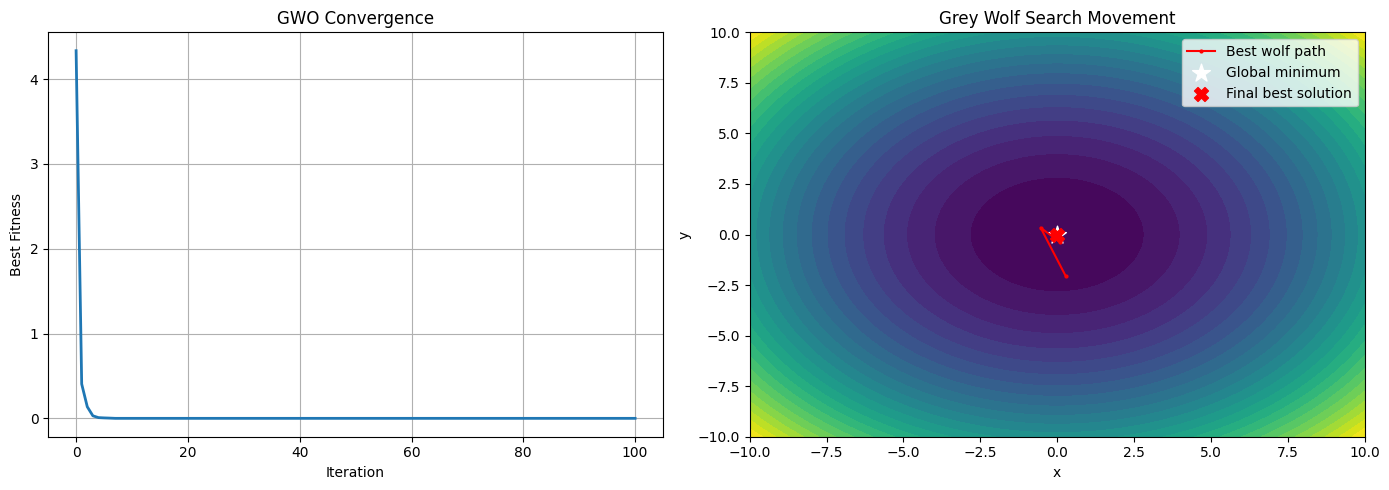

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Objective function
def fitness(x):
    return np.sum(x ** 2)

# GWO parameters
wolves = 20
iterations = 100
dimensions = 2
lower, upper = -10, 10

# Initialize wolf positions
X = np.random.uniform(lower, upper, (wolves, dimensions))
best_history = []
best_positions = []

for t in range(iterations):

    # Calculate fitness
    scores = np.array([fitness(w) for w in X])
    order = np.argsort(scores)

    alpha = X[order[0]].copy()
    beta = X[order[1]].copy()
    delta = X[order[2]].copy()

    best_history.append(fitness(alpha))
    best_positions.append(alpha.copy())

    # Decrease a from 2 to 0
    a = 2 - 2 * t / iterations

    # Update every wolf
    for i in range(wolves):
        new_positions = []

        for leader in [alpha, beta, delta]:
            r1 = np.random.rand(dimensions)
            r2 = np.random.rand(dimensions)

            A = 2 * a * r1 - a
            C = 2 * r2

            D = np.abs(C * leader - X[i])
            new_positions.append(leader - A * D)

        X[i] = np.mean(new_positions, axis=0)
        X[i] = np.clip(X[i], lower, upper)

# Final best solution
scores = np.array([fitness(w) for w in X])
best = X[np.argmin(scores)]

best_history.append(fitness(best))
best_positions.append(best.copy())
best_positions = np.array(best_positions)

print("Best solution (x, y):", best)
print("Minimum fitness:", fitness(best))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Convergence graph
axes[0].plot(best_history, linewidth=2)
axes[0].set_title("GWO Convergence")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Best Fitness")
axes[0].grid(True)

# 2. Search space and best wolf movement
x = np.linspace(lower, upper, 150)
y = np.linspace(lower, upper, 150)
Xg, Yg = np.meshgrid(x, y)
Z = Xg**2 + Yg**2

axes[1].contourf(Xg, Yg, Z, levels=30, cmap="viridis")
axes[1].plot(
    best_positions[:, 0],
    best_positions[:, 1],
    "r.-",
    markersize=4,
    label="Best wolf path"
)
axes[1].scatter(0, 0, color="white", marker="*", s=180,
                label="Global minimum")
axes[1].scatter(best[0], best[1], color="red", marker="X",
                s=100, label="Final best solution")
axes[1].set_title("Grey Wolf Search Movement")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].legend()

plt.tight_layout()
plt.show()
